<a href="https://colab.research.google.com/github/kim-guenyoung/LinearAlgebra/blob/main/%EB%A6%AC%EB%9D%BD%EC%BF%A0%EB%A7%88.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [31]:
%%writefile utils.py

import numpy as np
from matplotlib.patches import Polygon

def translate(p, dx, dy):
    #동차좌표계(homogeneous coordinate)으로 변환
    hp = np.array([p[0], p[1], 1.0])
    #이동 변환 행렬
    m = np.array([
        [1.0, 0.0, dx],
        [0.0, 1.0, dy],
        [0.0, 0.0, 1.0]
    ])
    #행렬 * 벡터
    q = np.dot(m, hp)
    return np.array([q[0], q[1]])

def rotate(p, theta):
    hp = np.array([p[0], p[1], 1.0])
    m = np.array([
        [np.cos(theta), -np.sin(theta), 0.0],
        [np.sin(theta), np.cos(theta), 0.0],
        [0.0, 0.0, 1.0]
    ])
    q = np.dot(m, hp)
    return np.array([q[0], q[1]])

def scale(p, sx, sy):
    hp = np.array([p[0], p[1], 1.0])
    m = np.array([
        [sx, 0.0, 0.0],
        [0.0, sy, 0.0],
        [0.0, 0.0, 1.0]
    ])
    q = np.dot(m, hp)
    return np.array([q[0], q[1]])

def shear_x(p, sx):
    hp = np.array([p[0], p[1], 1.0])
    m = np.array([
        [1.0, sx, 0.0],
        [0.0, 1.0, 0.0],
        [0.0, 0.0, 1.0]
    ])
    q = np.dot(m, hp)
    return np.array([q[0], q[1]])

def shear_y(p, sy):
    hp = np.array([p[0], p[1], 1.0])
    m = np.array([
        [1.0, 0.0, 0.0],
        [sy, 1.0, 0.0],
        [0.0, 0.0, 1.0]
    ])
    q = np.dot(m, hp)
    return np.array([q[0], q[1]])

def reflect_x(p):
    return np.array([p[0], -p[1]])

def reflect_y(p):
    return np.array([-p[0], p[1]])

def draw_shape(ax, pts, color, z=1, edge=None, width=2):
    ax.add_patch(Polygon(pts, closed=True, facecolor=color, edgecolor=edge, linewidth=width, zorder=z))

def draw_ears(ax, p1, p2, p3, p4, LEN):
    # 오른쪽 귀
    pts = [p1, p2, p3, p4]
    pts = [translate(p, -LEN/2, -LEN/2) for p in pts]
    pts = [scale(p, 0.70, 0.72) for p in pts]
    pts = [rotate(p, np.radians(-24)) for p in pts]
    pts = [translate(p, 110, 100) for p in pts]
    draw_shape(ax, pts, '#c78311', 1, '#614537', 3)
    # 원본 날개처럼 reflect_y로 왼쪽 귀 복제
    draw_shape(ax, [reflect_y(p) for p in pts], '#c78311', 1, '#614537', 3)

def draw_inner_ears(ax, p1, p2, p3, p4, LEN):
    pts = [p1, p2, p3, p4]
    pts = [translate(p, -LEN/2, -LEN/2) for p in pts]
    pts = [scale(p, 0.4, 0.40) for p in pts]
    pts = [rotate(p, np.radians(-24)) for p in pts]
    pts = [translate(p, 110, 100) for p in pts]
    draw_shape(ax, pts, '#ffda2e', 2)
    draw_shape(ax, [reflect_y(p) for p in pts], '#ffda2e', 2)

def draw_face(ax, p1, p2, p3, p4, LEN):
    pts = [p1, p2, p3, p4]
    pts = [translate(p, -LEN/2, -LEN/2) for p in pts]
    pts = [scale(p, 3, 2) for p in pts]
    pts[3] = shear_x(pts[3], 0.15) #왼쪽 위 머리
    pts[2] = shear_x(pts[2], -0.15) #오른쪽 위 머리
    draw_shape(ax, pts, '#c78311', edge='#614537', width=3)

def draw_eyes(ax, p1, p2, p3, p4, LEN):
    # 오른쪽 눈
    pts = [p1, p2, p3, p4]
    pts = [translate(p, -LEN/2, -LEN/2) for p in pts]
    pts = [scale(p, 0.3, 0.25) for p in pts]
    pts = [translate(p, 80, 0) for p in pts] #평행이동
    draw_shape(ax, pts, 'black')
    draw_shape(ax, [reflect_y(p) for p in pts], 'black') #y축 대칭이동

def draw_beard(ax, p1, p2, p3, p4, LEN):
    pts = [p1, p2, p3, p4]
    pts = [translate(p, -LEN/2, -LEN/2) for p in pts]
    pts = [scale(p, 0.9, 0.6) for p in pts]
    pts = [translate(p, 0, -50) for p in pts] #평행이동
    draw_shape(ax, pts, 'white')

def draw_nose(ax, p1, p2, p3, p4, LEN):
    # 코: 45도 회전
    pts = [p1, p2, p3, p4]
    pts = [translate(p, -LEN/2, -LEN/2) for p in pts]
    pts = [scale(p, 0.2, 0.2) for p in pts]
    pts = [rotate(p, np.radians(45)) for p in pts]
    pts = [translate(p, 0, -40) for p in pts]
    draw_shape(ax, pts, '#604335', 6)

def draw_mouth(ax, p1, p2, p3, p4, LEN):
    # 입 가운데 세로줄
    pts = [p1, p2, p3, p4]
    pts = [translate(p, -LEN/2, -LEN/2) for p in pts]
    pts = [scale(p, 0.05, 0.2) for p in pts]
    pts = [translate(p, 0, -55) for p in pts]
    draw_shape(ax, pts, '#604335')

    # 오른쪽 입꼬리: 사각형을 가늘게 만들고 회전
    pts = [p1, p2, p3, p4]
    pts = [translate(p, -LEN/2, -LEN/2) for p in pts]
    pts = [scale(p, 0.045, 0.23) for p in pts]
    pts = [rotate(p, np.radians(45)) for p in pts]
    pts = [translate(p, 10, -70) for p in pts]
    draw_shape(ax, pts, '#604335')
    # 왼쪽 입꼬리: 오른쪽 입꼬리 y축 대칭
    draw_shape(ax, [reflect_y(p) for p in pts], '#604335')

def draw_object(ax, LEN):
    p1 = np.array([0, 0])
    p2 = np.array([LEN, 0])
    p3 = np.array([LEN, LEN])
    p4 = np.array([0, LEN])

    draw_face(ax, p1, p2, p3, p4, LEN)
    draw_beard(ax, p1, p2, p3, p4, LEN)
    draw_ears(ax, p1, p2, p3, p4, LEN)
    draw_inner_ears(ax, p1, p2, p3, p4, LEN)
    draw_eyes(ax, p1, p2, p3, p4, LEN)
    draw_mouth(ax, p1, p2, p3, p4, LEN)
    draw_nose(ax, p1, p2, p3, p4, LEN)

Overwriting utils.py


In [39]:
%%writefile main.py

import numpy as np
import importlib
import matplotlib.pyplot as plt
import utils

importlib.reload(utils)

def main():
    LEN = 100

    fig, ax = plt.subplots(figsize=(6, 6))

    ax.set_xlim(-250, 250)
    ax.set_ylim(-250, 250)
    ax.set_aspect('equal')


    utils.draw_object(ax, LEN)
    plt.show()


if __name__ == "__main__":
    main()

Overwriting main.py


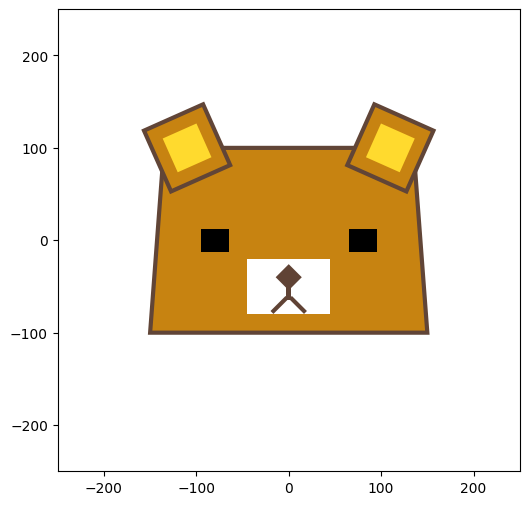

<Figure size 640x480 with 0 Axes>

In [40]:
%run main.py